In [1]:
#%pip install bias_correction

In [2]:
import pandas as pd
import numpy as np

from scipy.stats import percentileofscore

import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error,mean_absolute_error



In [3]:
data_pluie_satel=pd.read_excel("Data//donneées_chirps-1992-2024.xlsx").drop(["Unnamed: 0"],axis=1)

data_pluie_satel.head()

,date,BONOU
0,1982-01-01,0.0
1,1982-01-02,0.0
2,1982-01-03,0.0
3,1982-01-04,0.0
4,1982-01-05,0.0


In [4]:
data_pluie_meteo=pd.read_excel("Data//EEIA_data_pluie_à_traiter_bonou.xlsx")

data_pluie_meteo.head()

,Eg gh id,Name,Geogr1,Geogr2,Year,Eg el abbreviation,Name.1,Description,Month,Time,...,22,23,24,25,26,27,28,29,30,31
0,BJ0061P,BONOU,2.5,6.933333,1991,RR,Pluie jour,mm,1,06:00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,BJ0061P,BONOU,2.5,6.933333,1991,RR,Pluie jour,mm,2,06:00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,BJ0061P,BONOU,2.5,6.933333,1991,RR,Pluie jour,mm,3,06:00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,BJ0061P,BONOU,2.5,6.933333,1991,RR,Pluie jour,mm,4,06:00,...,0.0,0.0,0.0,0.0,0.0,20.2,0.0,36.6,4.2,NaN
4,BJ0061P,BONOU,2.5,6.933333,1991,RR,Pluie jour,mm,5,06:00,...,0.0,5.5,42.4,0.0,0.0,0.0,0.0,0.0,9.4,0.0


In [5]:
print(*data_pluie_meteo["Geogr1"].unique())

print(*data_pluie_meteo["Geogr2"].unique())

print(*data_pluie_meteo["Name"].unique())

print(*data_pluie_meteo["Eg gh id"].unique())

print(*data_pluie_meteo["Time"].unique())

print(*data_pluie_meteo["Description"].unique())

print(*data_pluie_meteo["Eg el abbreviation"].unique())

print(*data_pluie_meteo["Name.1"].unique())



2.5
6.933332999999999
BONOU
BJ0061P
06:00
mm
RR
Pluie jour


In [6]:
data_pluie_meteo=data_pluie_meteo.drop(["Geogr1","Geogr2","Name","Eg gh id","Time","Description","Eg el abbreviation","Name.1"],axis=1)

data_pluie_meteo.head()

,Year,Month,01,02,03,04,05,06,07,08,...,22,23,24,25,26,27,28,29,30,31
0,1991,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1991,2,0.0,0.0,0.0,0.0,4.1,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,1991,3,23.5,0.0,0.0,0.0,18.2,0.0,5.8,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1991,4,42.5,0.0,1.7,0.0,0.0,21.2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,20.2,0.0,36.6,4.2,NaN
4,1991,5,0.0,0.0,47.5,0.0,0.0,0.0,0.0,0.0,...,0.0,5.5,42.4,0.0,0.0,0.0,0.0,0.0,9.4,0.0


In [7]:
def rempl(x):
    annee=x.year
    mois=x.month
    jour=x.day
    if jour<10:
        jour=f"0{jour}"
    else :
        jour=f"{jour}"

    if len(data_pluie_meteo[(data_pluie_meteo.Year==annee) & (data_pluie_meteo.Month==mois)][jour])==0:
        return np.nan
    return data_pluie_meteo[(data_pluie_meteo.Year==annee) & (data_pluie_meteo.Month==mois)][jour].iloc[0]

data_pluie_satel["Pluie_meteo"]=data_pluie_satel["date"].apply(rempl)

In [8]:
data_pluie_satel

,date,BONOU,Pluie_meteo
0,1982-01-01,0.000000,NaN
1,1982-01-02,0.000000,NaN
2,1982-01-03,0.000000,NaN
3,1982-01-04,0.000000,NaN
4,1982-01-05,0.000000,NaN
...,...,...,...
15700,2024-12-26,0.000000,0.0
15701,2024-12-27,0.000000,0.0
15702,2024-12-28,1.547338,0.0
15703,2024-12-29,0.000000,0.0


In [9]:
data_pluie_satel=data_pluie_satel[~ (data_pluie_satel.date.dt.year<=1991)]

data_pluie_satel=data_pluie_satel[~((data_pluie_satel.date.dt.month==2) & (data_pluie_satel.date.dt.day==29))]
data_pluie_satel=data_pluie_satel[data_pluie_satel.date.dt.year!=2024]
data_pluie_satel.index=range(len(data_pluie_satel))

data_pluie_satel

,date,BONOU,Pluie_meteo
0,1992-01-01,0.041684,0.0
1,1992-01-02,0.000000,0.0
2,1992-01-03,0.000000,0.0
3,1992-01-04,0.000000,0.0
4,1992-01-05,0.000000,0.0
...,...,...,...
11675,2023-12-27,0.000000,0.0
11676,2023-12-28,0.000000,0.0
11677,2023-12-29,0.000000,0.0
11678,2023-12-30,0.000000,0.0


In [10]:
data=data_pluie_satel.copy()
data.isnull().sum()

date              0
BONOU             0
Pluie_meteo    1560
dtype: int64

In [11]:
def bilan(donnee):
    bilan=donnee.groupby(donnee.date.dt.year)["Pluie_meteo"].agg(total="size",manquante=lambda x:x.isnull().sum())
    bilan["Pourcentage valeur manquante"]=bilan["manquante"]*100/bilan["total"]
    return bilan

don=bilan(data)

don[0<don.manquante]

,total,manquante,Pourcentage valeur manquante
date,,,
1993,365,31,8.493151
1995,365,151,41.369863
1998,365,5,1.369863
2003,365,31,8.493151
2004,365,31,8.493151
2005,365,92,25.205479
2006,365,30,8.219178
2008,365,60,16.438356
2009,365,31,8.493151


In [12]:
vrai_val=data[data.date.dt.year==2010]["Pluie_meteo"].values

data=data.dropna()

vrai_val

array([ 0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. ,  8.5,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        8.7,  0. ,  0. , 11.5,  0. , 18. ,  0. ,  0. ,  0. ,  0. ,  9.5,
        0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. , 16.7,  0. ,
        0. ,  0. , 20.5,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. , 28.6,
        0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. , 12.7,  0. ,  0. , 21.5,
        0. ,  0. ,  0. , 10.8,  0. ,  0. , 32.2,  0. ,  0. ,  0. ,  0. ,
       18. ,  0. ,  0. ,  0. , 30.4,  0. ,  0. ,  0. , 11.1,  0. ,  0. ,
       12.6,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. ,  0. ,  0. ,  2.5,  0. , 37.4,  0. ,  0. ,  0. ,  0. ,  0. ,
        0. , 18.7,  0. , 15.5,  0. , 21.2,  0. ,  0

## Methode : Multiplicatif (Ratio Method)

*Calcule du coefficient de correction de biais F_b*

In [13]:
Fb=data[data["date"].dt.year != 2010]["Pluie_meteo"].mean()/data[data["date"].dt.year != 2010]["BONOU"].mean()

val_imput_Mult=data[data.date.dt.year==2010]["BONOU"].apply(lambda x : Fb*x).values

val_imput_Mult

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       5.57322902e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 3.32151675e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 1.72077345e+00, 7.30660443e-01,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.28266054e+00,
       1.28258900e+01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       6.97646926e-01, 0.00000000e+00, 8.16926393e-02, 6.21225768e-02,
      

## Methode : Quantile Mapping

In [14]:
def quantile_mapping_impute(obs_train, mod_train, mod_target):
    """
    Impute des données manquantes de station (obs) à partir de données 
    satellitaires (mod) par quantile mapping empirique.

    obs_train  : données STATION sur la période de référence (sans les manquantes)
    mod_train  : données SATELLITE sur la même période de référence
    mod_target : données SATELLITE sur la période à imputer (ex: année manquante)

    Retourne : les valeurs imputées de la station, de même taille que mod_target
    """
    obs_train = np.asarray(obs_train, dtype=float)
    mod_train = np.asarray(mod_train, dtype=float)
    mod_target = np.asarray(mod_target, dtype=float)

    corrected = np.full(mod_target.shape, np.nan)
    for i, val in enumerate(mod_target):
        if np.isnan(val):
            continue
        # rang percentile de la valeur satellite dans l'historique satellite
        p = percentileofscore(mod_train, val, kind="mean")
        # valeur station correspondant à ce même percentile
        corrected[i] = np.nanpercentile(obs_train, p)

    # la pluie ne peut pas être négative
    corrected = np.clip(corrected, 0, None)
    return corrected

In [15]:
val_imput_quant = quantile_mapping_impute(
    data[data["date"].dt.year != 2010]["Pluie_meteo"],       # station (référence)
    data[data["date"].dt.year != 2010]["BONOU"],  # satellite (référence)
    data.loc[data.date.dt.year == 2010, "BONOU"] # satellite à imputer -> 2010
)

val_imput_quant

array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
        15.5       ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.  

## Methode : Linear Scaling

*Calul des division de moyenne par age* 

In [16]:
# 1. Calcul des moyennes mensuelles à long terme
df=data[data.date.dt.year!=2010]

ds_mete=df.drop(["BONOU"],axis=1)
ds_sat=df.drop(["Pluie_meteo"],axis=1)

mean_obs = ds_mete.groupby(ds_mete.date.dt.month).mean()["Pluie_meteo"]
mean_sat = ds_sat.groupby(ds_sat.date.dt.month).mean()["BONOU"]
# 2. Calcul du facteur multiplicatif pour chaque mois
factor = mean_obs / mean_sat

val_imput_lin=((data[data.date.dt.year==2010]["BONOU"])*data[data.date.dt.year==2010].drop(["Pluie_meteo"],axis=1).date.dt.month.map(factor)).values

val_imput_lin

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       7.24589297e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 4.31838613e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 2.23722015e+00, 9.49949725e-01,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.64150673e+00,
       1.48421870e+01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       8.07320675e-01, 0.00000000e+00, 9.45351498e-02, 7.18885710e-02,
      

                     MAE       RMSE
Methode                            
Multiplicateur  6.622503  12.063764
Lineaire        6.816579  12.610169
Quantique       7.558014  15.141152


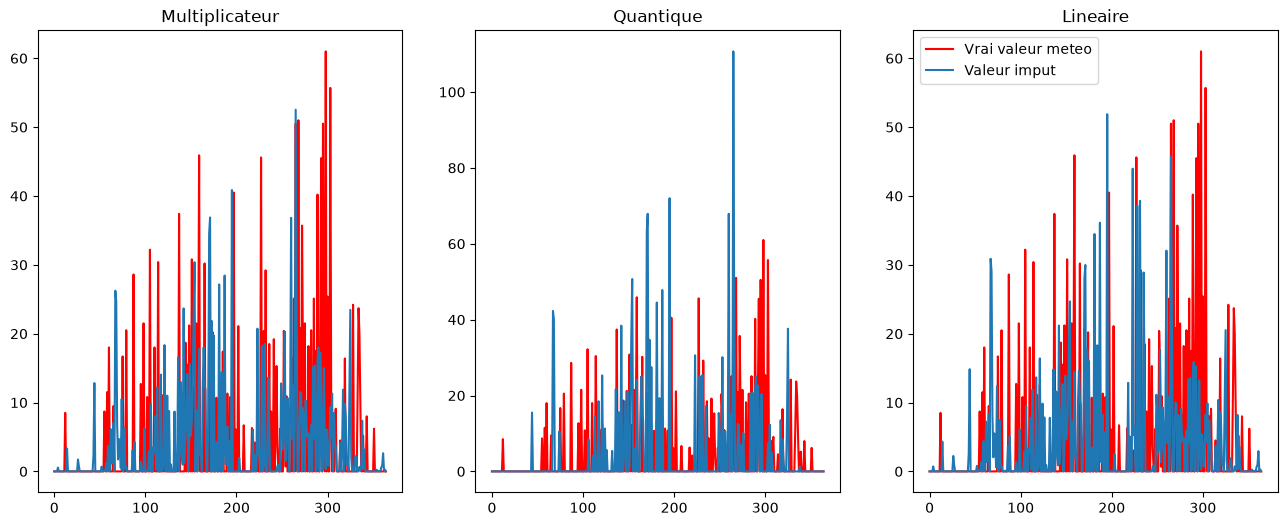

In [17]:
x=range(len(vrai_val))
print(pd.DataFrame({"Methode":["Multiplicateur","Quantique","Lineaire"],"MAE":[mean_absolute_error(vrai_val,val_imput_Mult),mean_absolute_error(vrai_val,val_imput_quant),
                                                    mean_absolute_error(vrai_val,val_imput_lin)],"RMSE":[np.sqrt(mean_squared_error(vrai_val,val_imput_Mult)),np.sqrt(mean_squared_error(vrai_val,val_imput_quant)),
                                                    np.sqrt(mean_squared_error(vrai_val,val_imput_lin))]}).sort_values(by="MAE").set_index("Methode"))
fig,axes=plt.subplots(1,3,figsize=(16,6))
axes[0].plot(x,vrai_val,label="Vrai valeur meteo",color="red")
axes[1].plot(x,vrai_val,label="Vrai valeur meteo",color="red")
axes[2].plot(x,vrai_val,label="Vrai valeur meteo",color="red")
axes[0].plot(x,val_imput_Mult,label="Valeur imput")
axes[0].set_title("Multiplicateur")
axes[1].plot(x,val_imput_quant,label="Valeur imput ")
axes[1].set_title("Quantique")
axes[2].plot(x,val_imput_lin,label="Valeur imput")
axes[2].set_title("Lineaire")
#plt.plot(x,data[data.date.dt.year==2010]["BONOU"],label="Vrai valeur satelite")

plt.legend()